In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
import scipy
import matplotlib.pyplot as plt
from pytorch_lightning import LightningModule
import segmentation_models_pytorch as smp

from matplotlib.colors import ListedColormap

from matplotlib import font_manager
from torch import nn

import tensorly as tl
from skimage.transform import resize
from scipy.ndimage import gaussian_filter
import pytorch_lightning as pl

import datetime as dt
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import segyio
from typing import Dict
import matplotlib.pyplot as plt
import numpy as np

from tqdm import tqdm

import blobfile as bf
import wandb
from scipy.ndimage import gaussian_filter
from net_test import UNO3D_cai
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import segyio
from typing import Dict
import matplotlib.pyplot as plt
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")   

In [35]:
cm_rtm=np.load("/home/max0b/no_vmb/colorbar_image.npy")
cm_rtm = ListedColormap(cm_rtm)
cm = ListedColormap(np.fromfile("/home/max0b/no_vmb/colorbar_ind (1).r@", dtype=np.float32).reshape(3,256).T)

In [36]:
def plot_slices(array, ids=None, size=5, width=1, ax=None, fig=None, recs=None, sous=None, fig_name=None, cbar_label='km/s', horizons=None, bounds=None, **kwargs):
    """
    Generate image slices from a 3D array.
    """
    if ids is None:
        ids = [array.shape[2]//2, array.shape[1]//2, array.shape[0]//2]

    if bounds is None:
        x = np.arange(array.shape[2])
        y = np.arange(array.shape[1])
        z = np.arange(array.shape[0])
    else:
        x = np.linspace(bounds[0], bounds[1], array.shape[2])
        y = np.linspace(bounds[0], bounds[2], array.shape[1])
        z = np.linspace(bounds[0], bounds[3], array.shape[0])
   
    
    grids = [x,y,z]

    if fig is None:
        fig = plt.figure(figsize=(1.5*size, size))
        
    if ax:
        gs = matplotlib.gridspec.GridSpecFromSubplotSpec(size, size, subplot_spec=ax, wspace=0.05, hspace=0.05)
    else:
        gs = matplotlib.gridspec.GridSpec(size, size, wspace=0.3, hspace=0.3)

    if fig is None:
        ax = fig.add_subplot(gs[0:(size-width), 0:(size-width)])
    
    # Upper left image
    ax0 = fig.add_subplot(gs[0:(size-width-2), 0:(size-width-2)])

    if bounds is None:
        im0 = ax0.imshow(array[ids[2]], **kwargs)
    else:
        im0 = ax0.imshow(array[ids[2]], extent=[bounds[0], bounds[1], bounds[2], bounds[0]], **kwargs)
    if horizons is not None:
        ax0.imshow(horizons[ids[2]], cmap='jet')
    ax0.hlines(grids[1][ids[1]],xmin=grids[0].min(),xmax=grids[0].max(), linestyles='--', color='black')
    ax0.text(grids[0].max(), grids[1][ids[1]], 'X1', horizontalalignment='right')
    ax0.text(grids[0].min(), grids[1][ids[1]], 'X0')
    ax0.text(grids[0][ids[0]], grids[1].min(), 'Y0', verticalalignment='top')
    ax0.text(grids[0][ids[0]], grids[1].max(), 'Y1')
    ax0.vlines(grids[0][ids[0]],ymin=grids[1].min(),ymax=grids[1].max(), linestyles='--', color='black')
    
    if bounds is not None:
        ax0.set_xlabel('km')
        ax0.set_ylabel('km')
    else:
        ax0.set_xlabel('nx')
        ax0.set_ylabel('ny')
    ax0.xaxis.set_ticks_position('top')
    ax0.xaxis.set_label_position('top')

    # Right image
    ax1 = fig.add_subplot(gs[0:(size-width-2), (size-width-2):])
    if bounds is None:
        ax1.imshow(array[:, :, ids[0]].T, **kwargs)
    else:
        ax1.imshow(array[:, :, ids[0]].T,extent=[bounds[0], bounds[3], bounds[1], bounds[0]], **kwargs)
    if horizons is not None:
        ax1.imshow(horizons[:, :, ids[0]],cmap='jet')
    ax1.hlines(grids[1][ids[1]],xmin=grids[2].min(),xmax=grids[2].max(), linestyles='--', color='black')
    ax1.vlines(grids[2][ids[2]],ymin=grids[1].min(),ymax=grids[1].max(), linestyles='--', color='black')
    ax1.text(grids[2][ids[2]], grids[1].max(), 'Y1', horizontalalignment='left', verticalalignment='bottom')
    ax1.text(grids[2][ids[2]], grids[1].min(), 'Y0', verticalalignment='top')
    ax1.yaxis.set_ticks_position('right')
    # ax1.xaxis.set_ticks_position('top')
    
    # Bottom image
    ax2 = fig.add_subplot(gs[(size-width-2):, 0:(size-width-2)])
    
    if bounds is None:
        ax2.imshow(array[:, ids[1], :],**kwargs)
    else:
        ax2.imshow(array[:, ids[1], :],extent=[bounds[0], bounds[1], bounds[3], bounds[0]], **kwargs)
    if horizons is not None:
        ax2.imshow(horizons[:, ids[1], :],cmap='jet')
    ax2.hlines(grids[2][ids[2]],xmin=grids[0].min(),xmax=grids[0].max(), linestyles='--', color='black')
    ax2.vlines(grids[0][ids[0]],ymin=grids[2].min(),ymax=grids[2].max(), linestyles='--', color='black')
    ax2.text(grids[0].max(), grids[2][ids[2]], 'X1', horizontalalignment='right', verticalalignment='top')
    ax2.text(grids[0].min(), grids[2][ids[2]], 'X0', verticalalignment='top')
    if bounds is not None:
        ax2.set_ylabel('km')
    else:
        ax2.set_ylabel('nz')
    

    # Add colorbar for the first image
    cbar = fig.colorbar(im0, ax=[ax0, ax1, ax2], orientation='vertical', fraction=0.05, pad=0.075)
    cbar.set_label(cbar_label, rotation=270-180, labelpad=15)
    
    if recs is not None:
        ax0.scatter(recs[0], recs[1], c='yellow', marker='v')
        
    if sous is not None:
        ax0.scatter(sous[0], sous[1], c='black', marker='*')
        
    if fig_name is not None:
        plt.savefig(fig_name)
        
    plt.show()


def tv_loss_3d(model: torch.Tensor) -> torch.Tensor:
    """
    Isotropic TV for 3D volume.
    Penalizes differences along depth (z), height (y), and width (x).
    """
    d, h, w = model.shape

    # differences along each axis (crop to align shapes)
    dz = model[:d-1, :h-1, :w-1] - model[1:,   :h-1, :w-1]
    dy = model[:d-1, :h-1, :w-1] - model[:d-1, 1:,   :w-1]
    dx = model[:d-1, :h-1, :w-1] - model[:d-1, :h-1, 1:]

    # isotropic TV: sqrt(dx^2 + dy^2 + dz^2)
    tv = torch.sqrt(dx.pow(2) + dy.pow(2) + dz.pow(2) + 1e-15)

    return tv.sum() / (d * h * w)

In [37]:
cm_rtm=np.load("/home/max0b/no_vmb/colorbar_image.npy")
cm_rtm = ListedColormap(cm_rtm)
cm = ListedColormap(np.fromfile("/home/max0b/no_vmb/colorbar_ind (1).r@", dtype=np.float32).reshape(3,256).T)

In [ ]:

font_path = '/home/max0b/no_rwi/Times_New_Roman.ttf'
font_manager.fontManager.addfont(font_path)


plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.sans-serif'] = ['Times New Roman']  


plt.rcParams['axes.unicode_minus'] = False


### Network

In [6]:
class OperatorBlock_3D(nn.Module):
    """
    Combines spectral convolution and pointwise convolution.
    """
    def __init__(self, in_codim, out_codim, dim1=None, dim2=None, dim3=None,
                 modes1=16, modes2=16, modes3=16, Normalize=True, Non_Lin=True):
        super(OperatorBlock_3D, self).__init__()

        self.conv = SpectralConv3d_Uno(in_codim, out_codim,
                                       dim1, dim2, dim3,
                                       modes1, modes2, modes3)
        self.w = pointwise_op_3D(in_codim, out_codim)
        self.normalize = Normalize
        self.non_lin = Non_Lin
        if Normalize:
            self.norm = nn.InstanceNorm3d(int(out_codim), affine=True)

    def forward(self, x):
        # 自动获取输入尺寸
        x1 = self.conv(x)
        x2 = self.w(x)
        x_out = x1 + x2

        if self.normalize:
            x_out = self.norm(x_out)
        if self.non_lin:
            x_out = F.gelu(x_out)
        return x_out

class SpectralConv3d_Uno(nn.Module):
    """
    3D Fourier layer supporting arbitrary input sizes.
    Performs FFT -> low-frequency filtering -> IFFT.
    """
    def __init__(self, in_codim, out_codim,
                 dim1=None, dim2=None, dim3=None,
                 modes1=16, modes2=16, modes3=16):
        super(SpectralConv3d_Uno, self).__init__()

        self.in_channels = int(in_codim)
        self.out_channels = int(out_codim)
        self.modes1 = int(modes1)
        self.modes2 = int(modes2)
        self.modes3 = int(modes3)

        # 初始化复权重 (实部,虚部)
        scale = (1 / (2 * in_codim)) ** 0.5
        self.weights1 = nn.Parameter(scale * torch.randn(in_codim, out_codim, self.modes1, self.modes2, self.modes3, 2))
        self.weights2 = nn.Parameter(scale * torch.randn(in_codim, out_codim, self.modes1, self.modes2, self.modes3, 2))
        self.weights3 = nn.Parameter(scale * torch.randn(in_codim, out_codim, self.modes1, self.modes2, self.modes3, 2))
        self.weights4 = nn.Parameter(scale * torch.randn(in_codim, out_codim, self.modes1, self.modes2, self.modes3, 2))

    def compl_mul3d(self, input, weights):
        """Complex multiplication in Fourier domain"""
        weights = torch.view_as_complex(weights)
        return torch.einsum("bixyz,ioxyz->boxyz", input, weights)

    def forward(self, x):
        """
        input: (B, Cin, D, H, W)
        output: (B, Cout, D, H, W)
        """
        B, Cin, D, H, W = x.shape
        # FFT
        x_ft = torch.fft.rfftn(x, s=(D, H, W), norm='forward')

        # 限制 modes 不超过输入大小的一半
        m1 = min(self.modes1, D // 2)
        m2 = min(self.modes2, H // 2)
        m3 = min(self.modes3, W // 2)

        # 初始化输出频谱
        out_ft = torch.zeros(B, self.out_channels, D, H, W // 2 + 1,
                             device=x.device, dtype=torch.cfloat)

        # 四个象限
        out_ft[:, :, :m1, :m2, :m3] = self.compl_mul3d(
            x_ft[:, :, :m1, :m2, :m3], self.weights1[:, :, :m1, :m2, :m3, :])
        out_ft[:, :, -m1:, :m2, :m3] = self.compl_mul3d(
            x_ft[:, :, -m1:, :m2, :m3], self.weights2[:, :, :m1, :m2, :m3, :])
        out_ft[:, :, :m1, -m2:, :m3] = self.compl_mul3d(
            x_ft[:, :, :m1, -m2:, :m3], self.weights3[:, :, :m1, :m2, :m3, :])
        out_ft[:, :, -m1:, -m2:, :m3] = self.compl_mul3d(
            x_ft[:, :, -m1:, -m2:, :m3], self.weights4[:, :, :m1, :m2, :m3, :])

        # IFFT 回物理空间
        x = torch.fft.irfftn(out_ft, s=(D, H, W), norm='forward')
        return x
import torch.nn.functional as F


class pointwise_op_3D(nn.Module):
    """
    Pointwise (1x1x1) convolution with optional spectral alias handling.
    Works for arbitrary input sizes.
    """
    def __init__(self, in_codim, out_codim):
        super(pointwise_op_3D, self).__init__()
        self.conv = nn.Conv3d(int(in_codim), int(out_codim), 1)

    def forward(self, x):
        return self.conv(x)
class UNO3D_cai(pl.LightningModule):
    """
    UNO3D 可变输入版本，固定 Fourier modes。
    """
    def __init__(self, in_width, width, pad=0, factor=3/4, pad_both=False):
        super(UNO3D_cai, self).__init__()
        self.in_width = in_width
        self.width = width
        self.padding = pad
        self.pad_both = pad_both
        self.loss_fn = torch.nn.MSELoss()
        # 输入映射
        self.fc_n1 = nn.Linear(in_width, width // 2)
        self.fc0 = nn.Linear(width // 2, width)

        # 固定 Fourier 模式数
        # 固定 Fourier 模式数
        # modes_conv0 = (96, 48, 48)
        # modes_conv1 = (64, 32, 32)
        # modes_conv2 = (32, 16, 16)
        # modes_conv6 = (32, 16, 16)
        # modes_conv7 = (64, 32, 32)
        # modes_conv8 = (96, 48, 48)
        
        modes_conv0 = (64, 48, 48)
        modes_conv1 = (50, 25, 25)
        modes_conv2 = (32, 16, 16)
        modes_conv6 = (32, 16, 16)
        modes_conv7 = (50, 25, 25)
        modes_conv8 = (64, 48, 48)       
        
        # modes_conv0 = (48, 24, 24)
        # modes_conv1 = (32, 16, 16)
        # modes_conv2 = (16, 8, 8)
        # modes_conv6 = (16, 8, 8)
        # modes_conv7 = (32, 16, 16)
        # modes_conv8 = (48, 24, 24)

        # 构建层结构
        self.conv0 = OperatorBlock_3D(width, int(2 * factor * width), None, None, None, *modes_conv0)
        self.conv1 = OperatorBlock_3D(int(2 * factor * width), int(4 * factor * width), None, None, None, *modes_conv1)
        self.conv2 = OperatorBlock_3D(int(4 * factor * width), int(8 * factor * width), None, None, None, *modes_conv2)
        self.conv6 = OperatorBlock_3D(int(8 * factor * width), int(4 * factor * width), None, None, None, *modes_conv6)
        self.conv7 = OperatorBlock_3D(int(8 * factor * width), int(2 * factor * width), None, None, None, *modes_conv7)
        self.conv8 = OperatorBlock_3D(int(4 * factor * width), int(2 * width), None, None, None, *modes_conv8)

        # 输出层
        self.fc1 = nn.Linear(3 * width, 4 * width)
        self.fc2 = nn.Linear(4 * width, 1)

    def forward(self, x):
        # 添加网格坐标 (x,y,z)
        grid = self.get_grid(x.shape, x.device)
        x = torch.cat((x, grid), dim=-1)

        # 输入映射
        x_fc = F.gelu(self.fc_n1(x))
        x_fc0 = F.gelu(self.fc0(x_fc))
        x_fc0 = x_fc0.permute(0, 4, 1, 2, 3)  # (B, C, D, H, W)

        # 主干
        x_c0 = self.conv0(x_fc0)
        x_c1 = self.conv1(x_c0)
        x_c2 = self.conv2(x_c1)

        x_c6 = self.conv6(x_c2)
        x_c6 = torch.cat([x_c6, x_c1], dim=1)

        x_c7 = self.conv7(x_c6)
        x_c7 = torch.cat([x_c7, x_c0], dim=1)

        x_c8 = self.conv8(x_c7)
        x_c8 = torch.cat([x_c8, x_fc0], dim=1)

        # Padding
        if self.padding != 0:
            if self.pad_both:
                x_c8 = x_c8[..., self.padding // 2:-self.padding // 2]
            else:
                x_c8 = x_c8[..., :-self.padding]

        x_c8 = x_c8.permute(0, 2, 3, 4, 1)
        x_fc1 = F.gelu(self.fc1(x_c8))
        x_out = self.fc2(x_fc1)
        return x_out.permute(0, 4, 1, 2, 3)

    def get_grid(self, shape, device):
        """
        shape: (B, D, H, W, C)
        """
        B, D, H, W = shape[0], shape[1], shape[2], shape[3]
        gridx = torch.linspace(0, 1, D, device=device).view(1, D, 1, 1, 1).repeat(B, 1, H, W, 1)
        gridy = torch.linspace(0, 1, H, device=device).view(1, 1, H, 1, 1).repeat(B, D, 1, W, 1)
        gridz = torch.linspace(0, 1, W, device=device).view(1, 1, 1, W, 1).repeat(B, D, H, 1, 1)
        grid = torch.cat((gridx, gridy, gridz), dim=-1)
        return grid
    def training_step(self, batch, batch_idx):
 
        # Main forward, loss computation, and metrics goes here
        x, y = batch
        x=x.permute(0, 2, 3, 4, 1).contiguous()
        #print(f"x_shape:{x.shape}")
        y_hat = self(x)
   

        data_loss = self.loss_fn(y_hat,y)
        eculedian_loss=F.pairwise_distance(y_hat, y, keepdim = True).mean()        
        loss = eculedian_loss +data_loss
        
        
        self.log("train_loss", loss, on_step=True, on_epoch=True,sync_dist=True)       
        
        self.log("eculedian_loss", eculedian_loss, on_step=True, on_epoch=True,sync_dist=True)    
        # Log learning rate
        optimizer = self.optimizers()
        lr = optimizer.param_groups[0]['lr']

        return loss

    
    def validation_step(self, batch, batch_idx):
        x, y = batch
        device = x.device
        x=x.permute(0, 2, 3, 4, 1).contiguous()
        # x, y = batch['x'], batch['y']
        y_hat = self(x)
        #loss_mse = self.loss_fn(y, y_hat)
        
        data_loss = self.loss_fn(y_hat,y)
        eculedian_loss=F.pairwise_distance(y_hat, y, keepdim = True).mean()        
        loss = eculedian_loss +data_loss
        
        
        self.log("val_loss", loss, on_step=True, on_epoch=True,sync_dist=True)       
        

    def configure_optimizers(self,lr=1e-3, step_size=50, gamma=0.7):
        # Return one or several optimizers
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        scheduler = {'scheduler': torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma),
                       'interval': 'epoch',  # 或 'step' 对于每步更新
                       'frequency': 1}
        return [optimizer], [scheduler]

In [ ]:
model = UNO3D_cai(in_width=2+3, width=12).to(device)
ckpt_path = "/home/max0b/IP_inversion_NO/test_inversion1/test_inversion1-2025-12-07-15-41-25/checkpoints/epoch=22-step=20309.ckpt"#
checkpoint = torch.load(ckpt_path,map_location='cpu')

state_dict = checkpoint['state_dict']


# #model = FNO2d(mode_x, mode_y, width, input_channel, output_channel)
# #model.load_state_dict(torch.load('../data/model_fno_curveA.pth'))
model.load_state_dict(state_dict)
model.eval()

UNO3D_cai(
  (loss_fn): MSELoss()
  (fc_n1): Linear(in_features=5, out_features=6, bias=True)
  (fc0): Linear(in_features=6, out_features=12, bias=True)
  (conv0): OperatorBlock_3D(
    (conv): SpectralConv3d_Uno()
    (w): pointwise_op_3D(
      (conv): Conv3d(12, 18, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    )
    (norm): InstanceNorm3d(18, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
  )
  (conv1): OperatorBlock_3D(
    (conv): SpectralConv3d_Uno()
    (w): pointwise_op_3D(
      (conv): Conv3d(18, 36, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    )
    (norm): InstanceNorm3d(36, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
  )
  (conv2): OperatorBlock_3D(
    (conv): SpectralConv3d_Uno()
    (w): pointwise_op_3D(
      (conv): Conv3d(36, 72, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    )
    (norm): InstanceNorm3d(72, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
  )
  (conv6): OperatorBlock_3D(
    (conv): SpectralConv3d

In [20]:
index=125

In [21]:
data=np.load(f"/data/max0b/synthoseis_example/2025_11_23_3D_data_imp/val/seismic/data{index}.npy")
label=np.load(f"/data/max0b/synthoseis_example/2025_11_23_3D_data_imp/val/impedance/data{index}.npy")
print(data.shape,label.shape)

(509, 128, 128) (509, 128, 128)


In [22]:
data=np.load(f"/data/max0b/synthoseis_example/2025_11_23_3D_data_imp/val/seismic/data{index}.npy")
label=np.load(f"/data/max0b/synthoseis_example/2025_11_23_3D_data_imp/val/impedance/data{index}.npy")
 

sigma = 15
input_1 = gaussian_filter(label, sigma=sigma)

inputs_numpy = np.stack([input_1, label], axis=0)

inputs = torch.tensor(inputs_numpy,dtype=torch.float32).unsqueeze(0)

label = torch.tensor(data,dtype=torch.float32).unsqueeze(0).unsqueeze(0)

print(inputs.shape,label.shape)

torch.Size([1, 2, 509, 128, 128]) torch.Size([1, 1, 509, 128, 128])


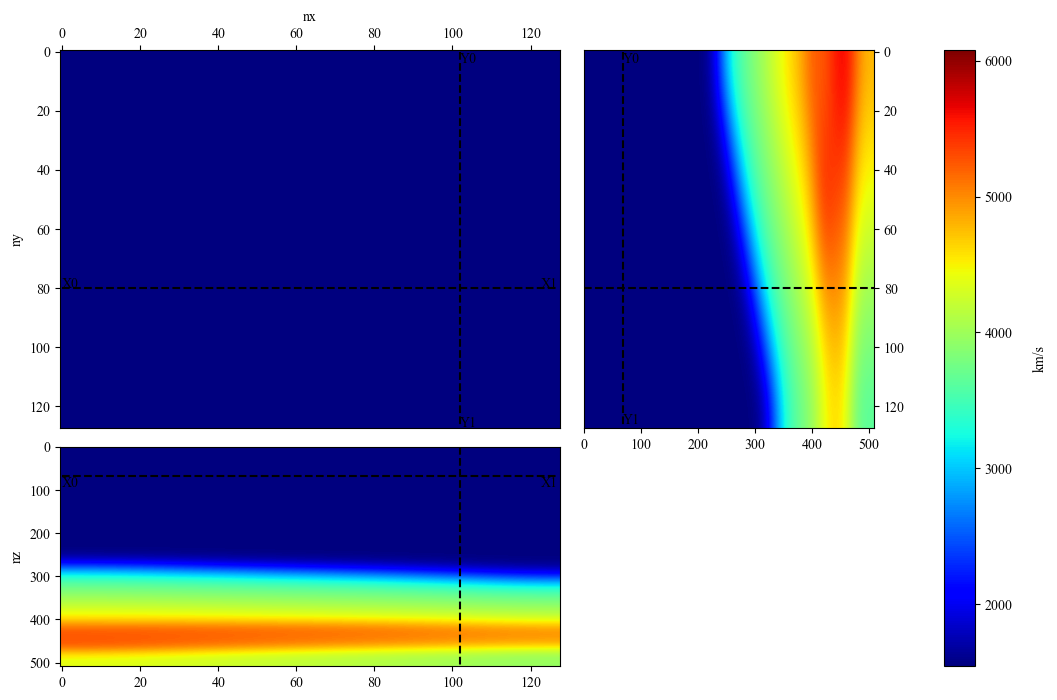

In [29]:
vmin,vmax=np.percentile(inputs[0,1],[1,99])
plot_slices(inputs[0,0], ids=[102,80,68], aspect='auto', size=8, interpolation='bicubic', cmap='jet', vmin=vmin,vmax=vmax
     
                #,bounds=[0,x.max(),y.max(),z.max()]
               )

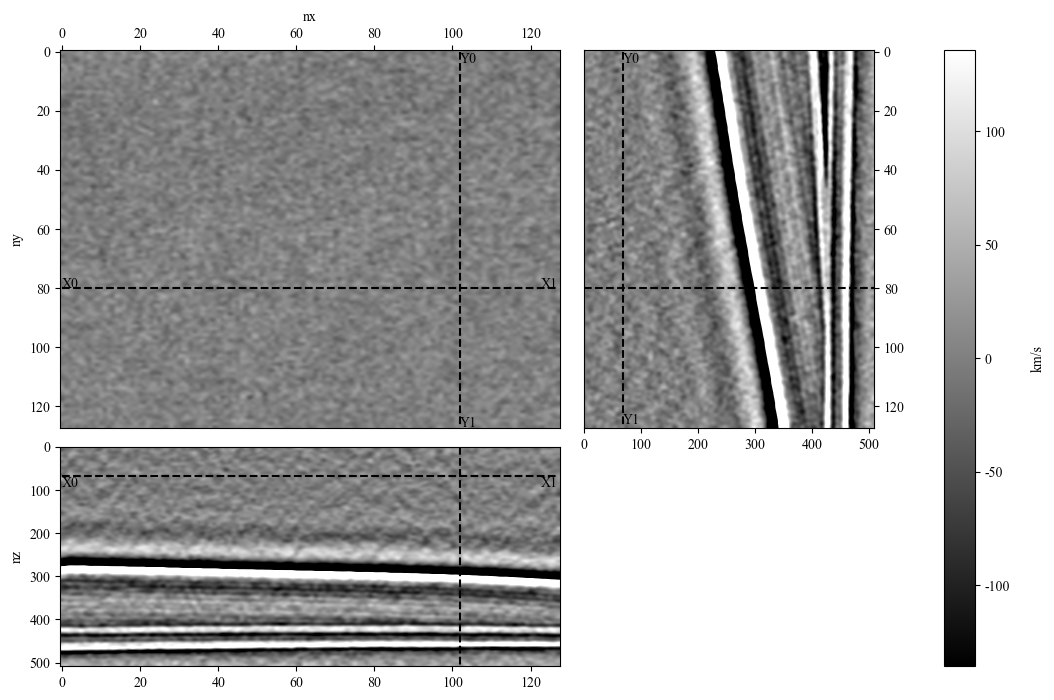

In [30]:
vm=np.percentile(label[0,0],95)
plot_slices(label[0,0], ids=[102,80,68], aspect='auto', size=8, interpolation='bicubic', cmap='gray', vmin=-vm,vmax=vm
     
                #,bounds=[0,x.max(),y.max(),z.max()]
               )

In [31]:
inputs = torch.tensor(inputs,dtype=torch.float32)
print(inputs.shape)
model_network=model.to(device)
model_network.eval()
#inputs=inputs.unsqueeze(0).to(torch.float32)
print(inputs.shape)
print(inputs.dtype)
y_hat = model_network(inputs.permute(0, 2, 3, 4, 1).contiguous().to(device))
outputs=y_hat.squeeze().cpu().detach().numpy()

torch.Size([1, 2, 509, 128, 128])
torch.Size([1, 2, 509, 128, 128])
torch.float32


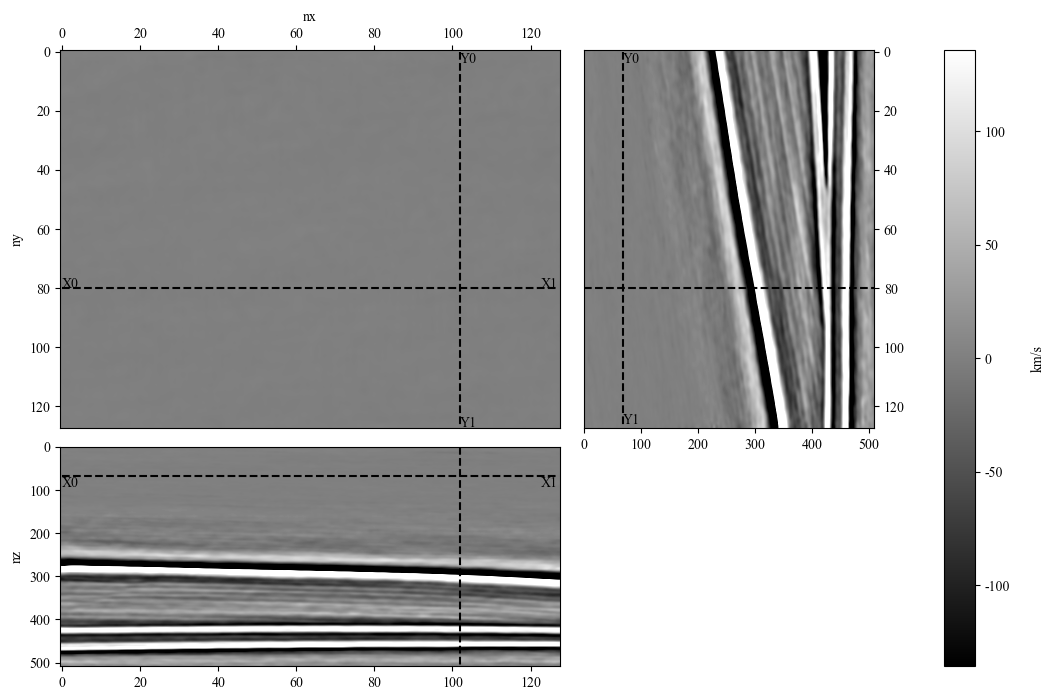

: 

In [ ]:
plot_slices(outputs,  ids=[102,80,68], aspect='auto', size=8, interpolation='bicubic', cmap='gray', vmin=-vm,vmax=vm )

In [12]:
label.shape

torch.Size([1, 1, 509, 128, 128])

### Inversion

In [ ]:
model_network=model.to(device)
model_network.eval()
#==============hyperparameters=================#
gain=1
lr=10
#===============================================#
mseloss=torch.nn.MSELoss()
maeloss=torch.nn.L1Loss()

init_v_tmp = scipy.ndimage.gaussian_filter(inputs[0,0].numpy(), sigma=15)  # default 20
init_v = torch.tensor(init_v_tmp.copy(),dtype=torch.float32).to(device).unsqueeze(0).unsqueeze(0)

init_v.requires_grad_(True)  


input_1=torch.tensor(input_1,dtype=torch.float32).unsqueeze(0).unsqueeze(0)


labels=label*gain
#init_v = torch.tensor(input_2,dtype=torch.float32).to(device).requires_grad_(True)
# Optimize the initial velocity model as the variable
optim = torch.optim.Adam([init_v], lr=lr)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=50, gamma=0.99)
#optim = torch.optim.SGD([init_v], lr=500)
model_network.to(device)
model_network.eval()
loss_all = []
print(labels.shape)
# Define the data on the surface, if None, denoting using the data on the whole domain, while for 1, denoting the surface data
data_on_the_surface = None
for i in range(250):
    
    print(input_1.shape,init_v.shape)
    
    inputs_no, outputs_no = torch.cat([torch.tensor(input_1,dtype=torch.float32).to(device), init_v], dim=1), torch.tensor(labels,dtype=torch.float32).to(device)
    
    preds = model_network(inputs_no.permute(0, 2, 3, 4, 1).contiguous().to(device))
    #pde_loss = equation_fd(0.0125, preds - inputs[:,0:2], 1.0/ (inputs[:,2:3] ** 2), 1.0 / (inputs[:,3:4] **2), inputs[:,0:1] , inputs[:,1:2] , torch.tensor(test_samples['x'][4:5]).unsqueeze(0).to(device)) * 1e-5
    
    # using the physical loss and the data loss
    loss = maeloss(preds, outputs_no)*1+ mseloss(preds, outputs_no)*0.01
    optim.zero_grad()
    loss.backward()
    optim.step()
    
    scheduler.step()
    torch.nn.utils.clip_grad_norm_([init_v], max_norm=0.0)
        
    with torch.no_grad():
        grad_np = init_v.grad.squeeze().cpu().numpy()
        grad_smoothed = scipy.ndimage.gaussian_filter(grad_np, sigma=0)
        init_v.grad.copy_(torch.tensor(grad_smoothed).unsqueeze(0).unsqueeze(0).to(device))
    if i % 5 == 0:
        print(f'Epoch {i}, loss {loss.item()}')
    loss_all.append(loss.item())
    # if i % 10 == 0:
    #     plt.figure()
    #     vm=np.percentile(preds[0,0,...].cpu().detach().numpy(), 99)
    #     plt.imshow(preds[0,0,...].cpu().detach().numpy(),cmap="gray",vmin=-vm,vmax=vm)
    #     plt.show()
    
plt.figure()
plt.plot(loss_all)
plt.yscale('log')

In [ ]:
outputs=init_v.squeeze().cpu().detach().numpy()
print(outputs.shape)
vmin,vmax=np.percentile(inputs[0,1],[1,99])
plot_slices(outputs, ids=[102,102,212], aspect='auto', size=8, interpolation='bicubic', cmap='jet', vmin=vmin,vmax=vmax
     
                #,bounds=[0,x.max(),y.max(),z.max()]
               )

(509, 128, 128)


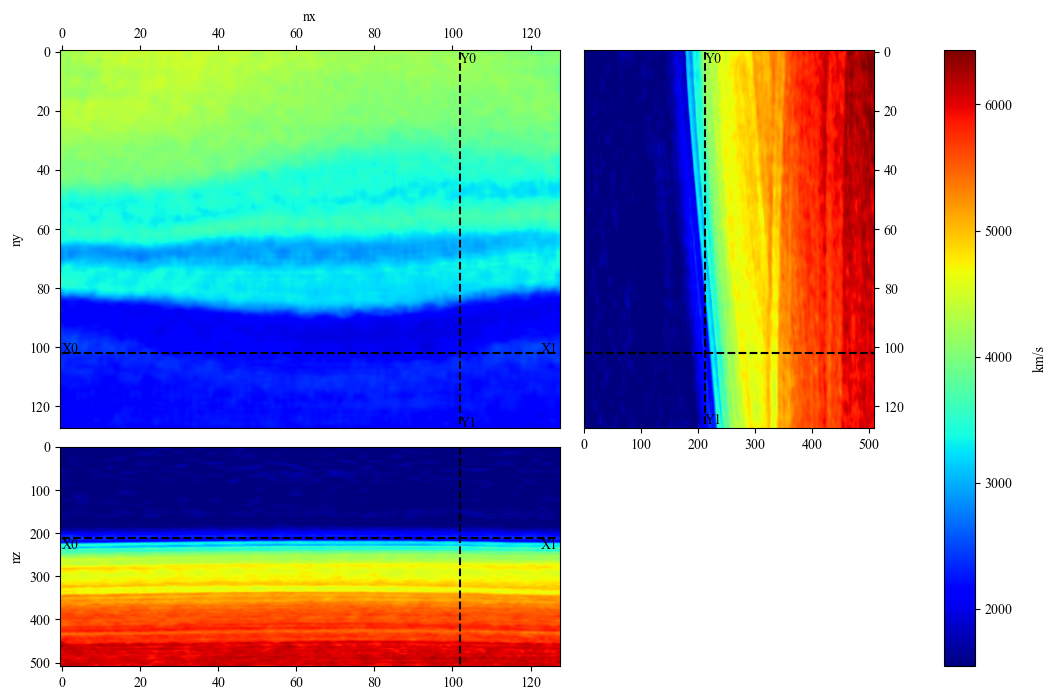

In [25]:
vmin,vmax=np.percentile(inputs[0,1],[1,99])
plot_slices(outputs, ids=[102,102,212], aspect='auto', size=8, interpolation='bicubic', cmap='jet', vmin=vmin,vmax=vmax
     
                #,bounds=[0,x.max(),y.max(),z.max()]
               )

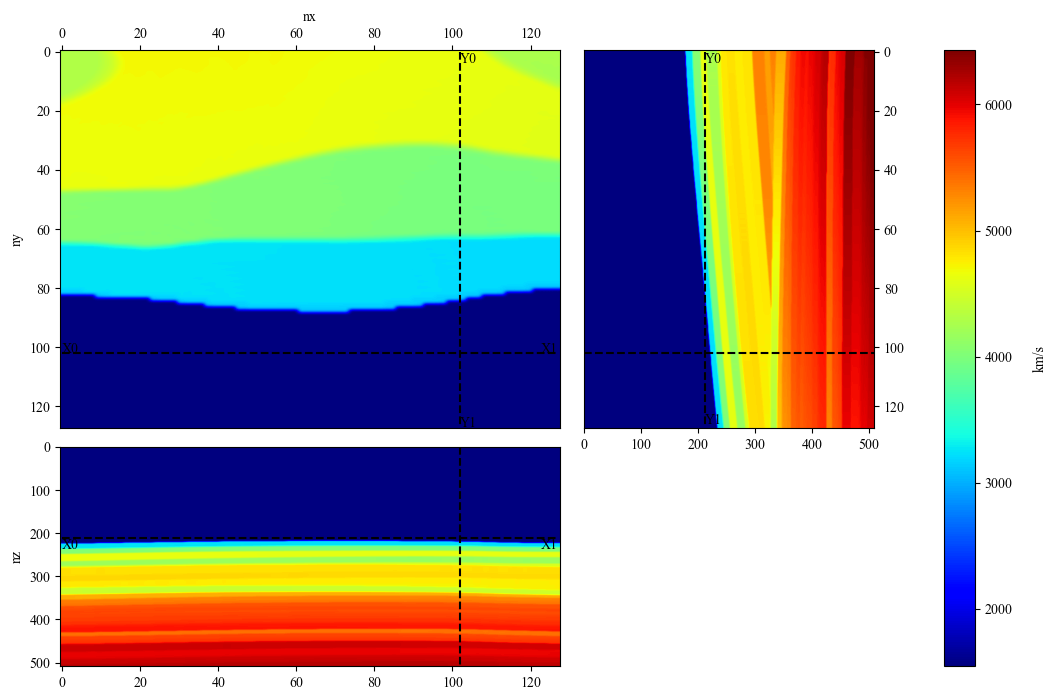

In [26]:
vmin,vmax=np.percentile(inputs[0,1],[1,99])
plot_slices(inputs[0,1], ids=[102,102,212], aspect='auto', size=8, interpolation='bicubic', cmap='jet', vmin=vmin,vmax=vmax
           #,bounds=[0,x.max(),y.max(),z.max()]
               )

In [20]:
import os
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import segyio
from typing import Dict
import matplotlib.pyplot as plt

In [21]:
# Load seismic data
segy_file="/home/max0b/IP_inversion_NO/B-IntraSeismic-pub/data/01p07ful.sgy"
with segyio.open(segy_file) as f:
    d_ = segyio.cube(f).transpose(2, 1, 0)[:]
    xlines = f.xlines if hasattr(f, 'xlines') else np.arange(d_.shape[2])
    ilines = f.ilines if hasattr(f, 'ilines') else np.arange(d_.shape[1])
    samples = f.samples[:] if hasattr(f, 'samples') else np.arange(d_.shape[0])

In [22]:
d_.shape

(1001, 468, 249)

In [23]:
ilines

array([1716, 1717, 1718, 1719, 1720, 1721, 1722, 1723, 1724, 1725, 1726,
       1727, 1728, 1729, 1730, 1731, 1732, 1733, 1734, 1735, 1736, 1737,
       1738, 1739, 1740, 1741, 1742, 1743, 1744, 1745, 1746, 1747, 1748,
       1749, 1750, 1751, 1752, 1753, 1754, 1755, 1756, 1757, 1758, 1759,
       1760, 1761, 1762, 1763, 1764, 1765, 1766, 1767, 1768, 1769, 1770,
       1771, 1772, 1773, 1774, 1775, 1776, 1777, 1778, 1779, 1780, 1781,
       1782, 1783, 1784, 1785, 1786, 1787, 1788, 1789, 1790, 1791, 1792,
       1793, 1794, 1795, 1796, 1797, 1798, 1799, 1800, 1801, 1802, 1803,
       1804, 1805, 1806, 1807, 1808, 1809, 1810, 1811, 1812, 1813, 1814,
       1815, 1816, 1817, 1818, 1819, 1820, 1821, 1822, 1823, 1824, 1825,
       1826, 1827, 1828, 1829, 1830, 1831, 1832, 1833, 1834, 1835, 1836,
       1837, 1838, 1839, 1840, 1841, 1842, 1843, 1844, 1845, 1846, 1847,
       1848, 1849, 1850, 1851, 1852, 1853, 1854, 1855, 1856, 1857, 1858,
       1859, 1860, 1861, 1862, 1863, 1864, 1865, 18

In [24]:
xlines

array([ 956,  957,  958,  959,  960,  961,  962,  963,  964,  965,  966,
        967,  968,  969,  970,  971,  972,  973,  974,  975,  976,  977,
        978,  979,  980,  981,  982,  983,  984,  985,  986,  987,  988,
        989,  990,  991,  992,  993,  994,  995,  996,  997,  998,  999,
       1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010,
       1011, 1012, 1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021,
       1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032,
       1033, 1034, 1035, 1036, 1037, 1038, 1039, 1040, 1041, 1042, 1043,
       1044, 1045, 1046, 1047, 1048, 1049, 1050, 1051, 1052, 1053, 1054,
       1055, 1056, 1057, 1058, 1059, 1060, 1061, 1062, 1063, 1064, 1065,
       1066, 1067, 1068, 1069, 1070, 1071, 1072, 1073, 1074, 1075, 1076,
       1077, 1078, 1079, 1080, 1081, 1082, 1083, 1084, 1085, 1086, 1087,
       1088, 1089, 1090, 1091, 1092, 1093, 1094, 1095, 1096, 1097, 1098,
       1099, 1100, 1101, 1102, 1103, 1104, 1105, 11

In [29]:
seismic_data=d_*180
print(seismic_data.shape,seismic_data.min(),seismic_data.max())

(1001, 468, 249) -776.6893 628.2386


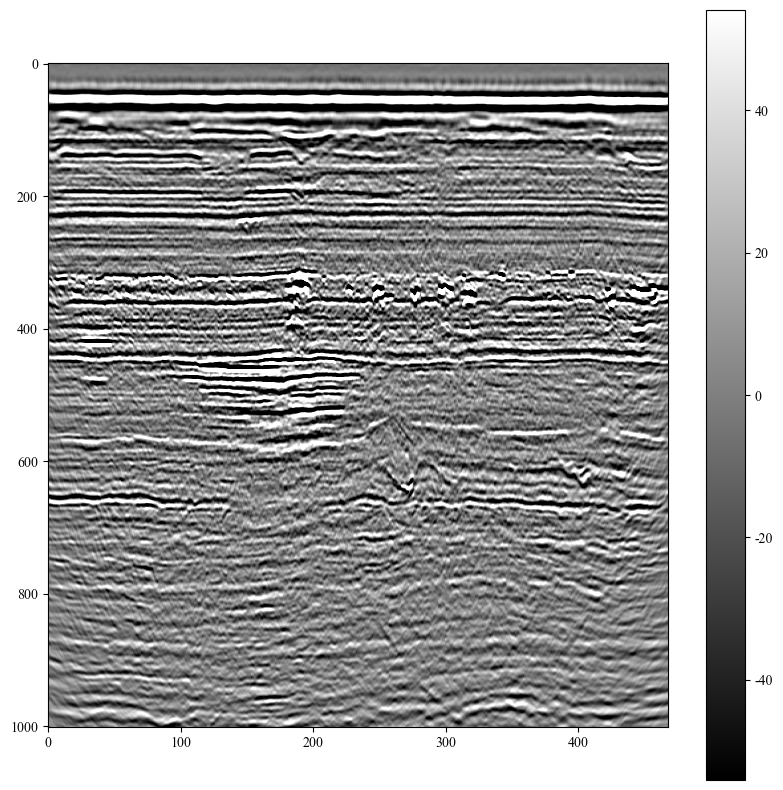

In [30]:
vm=np.percentile(seismic_data,95)
plt.figure(figsize=(10,10))
plt.imshow(seismic_data[:,:,115],cmap="gray",vmin=-vm,vmax=vm,aspect=0.5)
plt.colorbar()

In [ ]:

Back_model=np.load("/home/max0b/IP_inversion_NO/4DProximal/data/Sleipner/Sleipner_impedance_model.npy")
Back_model_3d = np.repeat(Back_model[:, :, None], 249, axis=2)
bg_model=Back_model_3d[350:550,50:250,0:200]
data=seismic_data[350:550,50:250,0:200]
#============================================================#

# Back_model=np.load("/home/max0b/IP_inversion_NO/4DProximal/data/Sleipner/Sleipner_impedance_model.npy")
# Back_model_3d = np.repeat(Back_model[:, :, None], 249, axis=2)
# bg_model=Back_model_3d[0:150,:234,:]
# data=seismic_data[0:150,:234,:]

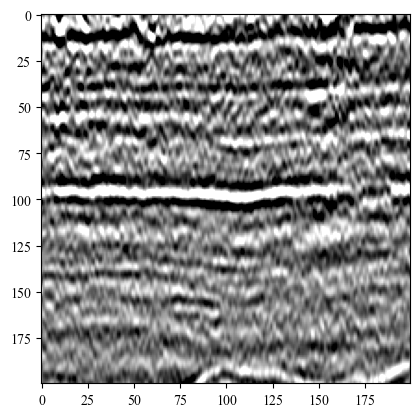

In [32]:
plt.imshow(data[:,:,80],cmap="gray",vmin=-vm,vmax=vm,aspect=1)

In [33]:
inputs= np.stack([bg_model, data], axis=0)
inputs=torch.tensor(inputs,dtype=torch.float32).unsqueeze(0)
print(inputs.shape)

torch.Size([1, 2, 200, 200, 200])


In [34]:


def tv_loss_3d(model: torch.Tensor) -> torch.Tensor:
    """
    Isotropic TV for 3D volume.
    Penalizes differences along depth (z), height (y), and width (x).
    """
    d, h, w = model.shape

    # differences along each axis (crop to align shapes)
    dz = model[:d-1, :h-1, :w-1] - model[1:,   :h-1, :w-1]
    dy = model[:d-1, :h-1, :w-1] - model[:d-1, 1:,   :w-1]
    dx = model[:d-1, :h-1, :w-1] - model[:d-1, :h-1, 1:]

    # isotropic TV: sqrt(dx^2 + dy^2 + dz^2)
    tv = torch.sqrt(dx.pow(2) + dy.pow(2) + dz.pow(2) + 1e-15)

    return tv.sum() / (d * h * w)


torch.Size([1, 1, 200, 200, 200])


Epoch 0, loss 20862.5703125
Epoch 5, loss 12237.26171875
Epoch 10, loss 9162.302734375
Epoch 15, loss 7358.50244140625
Epoch 20, loss 6150.505859375
Epoch 25, loss 5332.19189453125
Epoch 30, loss 4791.03759765625
Epoch 35, loss 4418.224609375
Epoch 40, loss 4155.65966796875
Epoch 45, loss 3961.65625
Epoch 50, loss 3814.80859375
Epoch 55, loss 3700.42626953125
Epoch 60, loss 3608.561279296875
Epoch 65, loss 3533.513916015625
Epoch 70, loss 3470.81494140625
Epoch 75, loss 3417.4970703125
Epoch 80, loss 3371.42822265625
Epoch 85, loss 3330.98779296875
Epoch 90, loss 3295.06689453125
Epoch 95, loss 3262.8046875


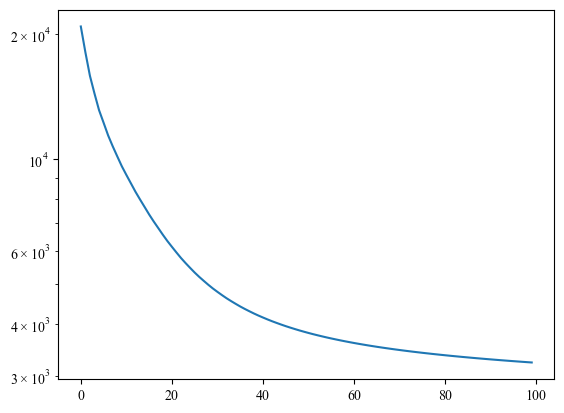

In [ ]:
model_network=model.to(device)
model_network.eval()
#==============hyperparameters=================#
gain=3
lr=50
#===============================================#
mseloss=torch.nn.MSELoss()
maeloss=torch.nn.L1Loss()

init_v_tmp = scipy.ndimage.gaussian_filter(bg_model, sigma=0)  # default 20
init_v = torch.tensor(init_v_tmp.copy(),dtype=torch.float32).to(device).unsqueeze(0).unsqueeze(0)

init_v.requires_grad_(True)  # 👈 最后一步设置，保证是 leaf


input_1=torch.tensor(bg_model,dtype=torch.float32).unsqueeze(0).unsqueeze(0)


labels=torch.tensor(data).unsqueeze(0).unsqueeze(0)*gain
#init_v = torch.tensor(input_2,dtype=torch.float32).to(device).requires_grad_(True)
# Optimize the initial velocity model as the variable
optim = torch.optim.Adam([init_v], lr=lr)
scheduler = torch.optim.lr_scheduler.StepLR(optim, step_size=50, gamma=0.99)
#optim = torch.optim.SGD([init_v], lr=500)
model_network.to(device)
model_network.eval()
loss_all = []
print(labels.shape)
# Define the data on the surface, if None, denoting using the data on the whole domain, while for 1, denoting the surface data
data_on_the_surface = None
for i in range(100):
    
    
    inputs_no, outputs_no = torch.cat([torch.tensor(input_1,dtype=torch.float32).to(device), init_v], dim=1), torch.tensor(labels,dtype=torch.float32).to(device)
    
    preds = model_network(inputs_no.permute(0, 2, 3, 4, 1).contiguous().to(device))
    #pde_loss = equation_fd(0.0125, preds - inputs[:,0:2], 1.0/ (inputs[:,2:3] ** 2), 1.0 / (inputs[:,3:4] **2), inputs[:,0:1] , inputs[:,1:2] , torch.tensor(test_samples['x'][4:5]).unsqueeze(0).to(device)) * 1e-5
    
    # using the physical loss and the data loss
    loss = maeloss(preds, outputs_no)*0+ mseloss(preds, outputs_no)*1+tv_loss_3d(init_v[0,0])*5
    optim.zero_grad()
    loss.backward()
    optim.step()

    scheduler.step()
    torch.nn.utils.clip_grad_norm_([init_v], max_norm=0.0)

    with torch.no_grad():
        grad_np = init_v.grad.squeeze().cpu().numpy()
        grad_smoothed = scipy.ndimage.gaussian_filter(grad_np, sigma=0)
        init_v.grad.copy_(torch.tensor(grad_smoothed).unsqueeze(0).unsqueeze(0).to(device))
    if i % 5 == 0:
        print(f'Epoch {i}, loss {loss.item()}')
    loss_all.append(loss.item())
    # if i % 10 == 0:
    #     plt.figure()
    #     vm=np.percentile(preds[0,0,...].cpu().detach().numpy(), 99)
    #     plt.imshow(preds[0,0,...].cpu().detach().numpy(),cmap="gray",vmin=-vm,vmax=vm)
    #     plt.show()
    
plt.figure()
plt.plot(loss_all)
plt.yscale('log')

In [36]:
outputs=init_v.squeeze().cpu().detach().numpy()
print(outputs.shape)


(200, 200, 200)


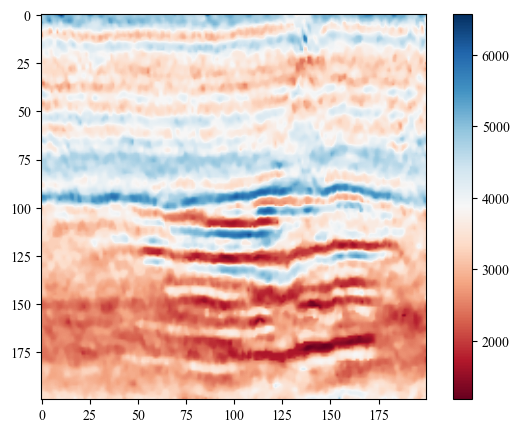

In [37]:
plt.figure(figsize=(7,5))
plt.imshow(outputs[...,115],cmap="RdBu",interpolation="bilinear")
plt.colorbar()

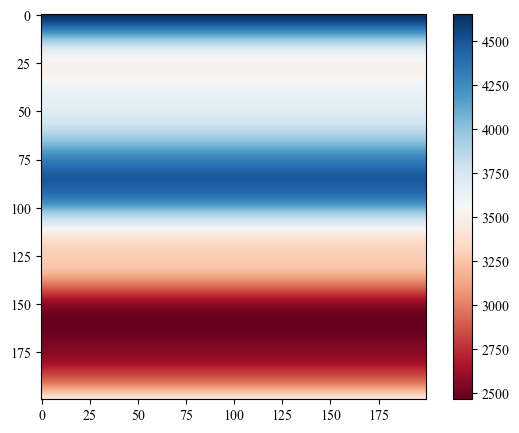

In [38]:
plt.figure(figsize=(7,5))
plt.imshow(bg_model[...,115],cmap="RdBu")
plt.colorbar()

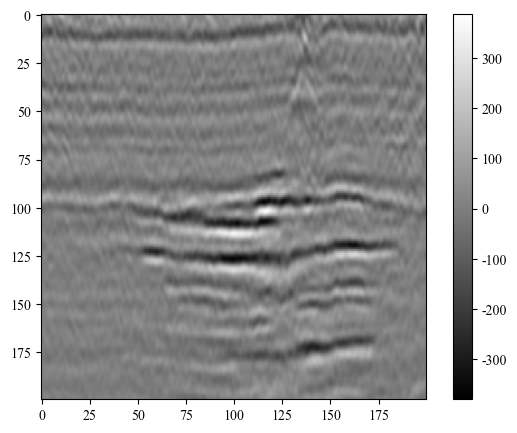

In [39]:
plt.figure(figsize=(7,5))
plt.imshow(data[...,115],cmap="gray")


plt.colorbar()

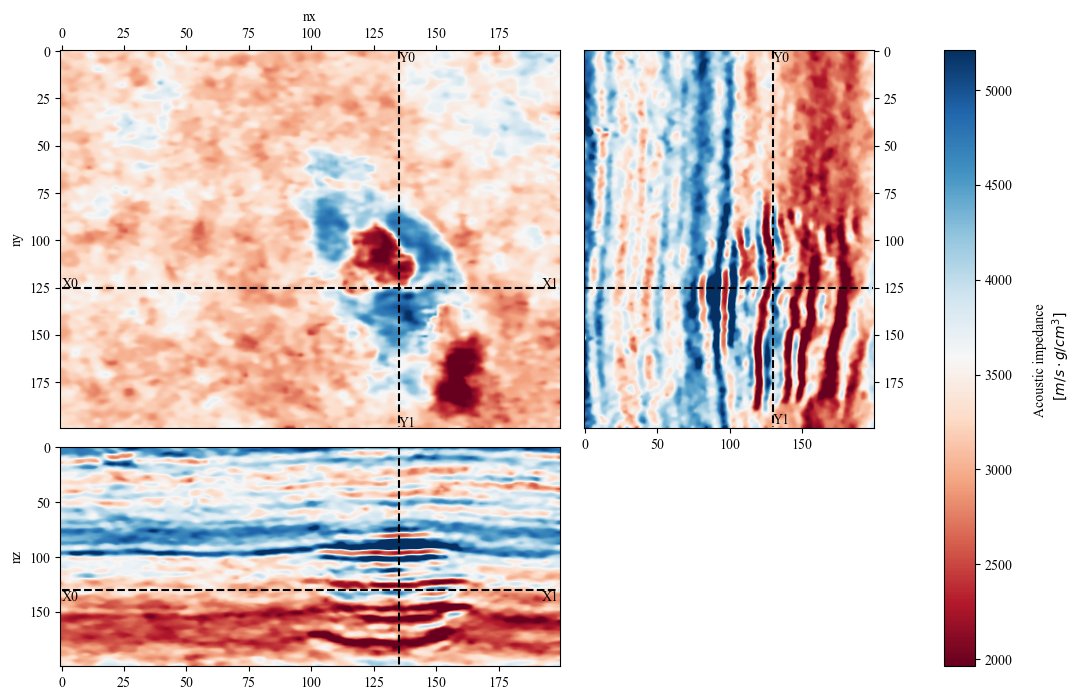

In [40]:
vmin,vmax=np.percentile(outputs,[1,99])
plot_slices(outputs, ids=[135,125,130], aspect='auto', size=8, interpolation='bicubic', cbar_label='Acoustic impedance \n $[m/s \cdot g/cm^3]$',cmap='RdBu',vmin=vmin,vmax=vmax)

In [32]:
np.save("/home/max0b/IP_inversion_NO/minor.npy",outputs)

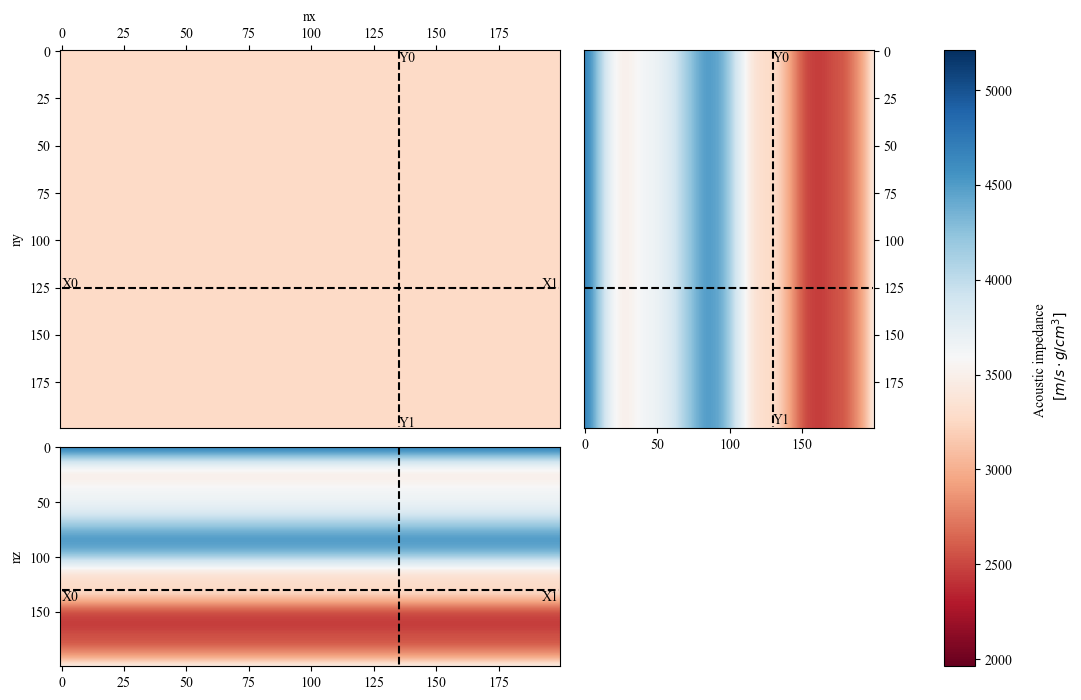

In [41]:
plot_slices(bg_model, ids=[135,125,130], aspect='auto', size=8, cbar_label='Acoustic impedance \n $[m/s \cdot g/cm^3]$', interpolation='bicubic',cmap='RdBu',vmin=vmin,vmax=vmax)

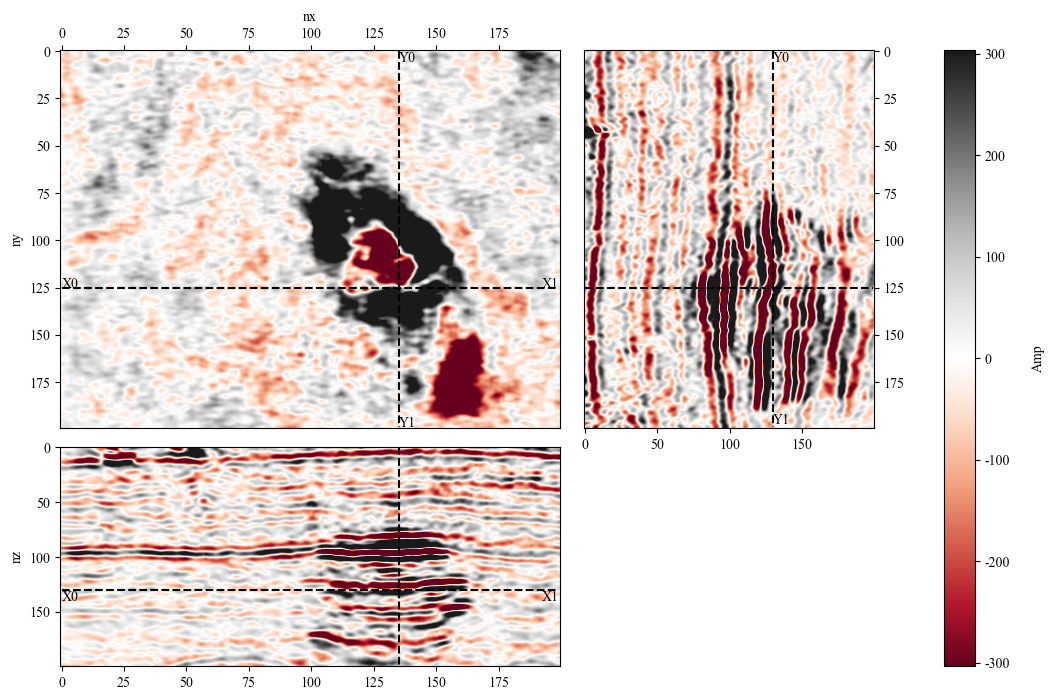

In [42]:
vm=np.percentile(data*gain,98)
plot_slices(data*gain, ids=[135,125,130], aspect='auto', size=8, cbar_label='Amp', interpolation='bicubic', cmap="RdGy",vmin=-vm,vmax=vm)

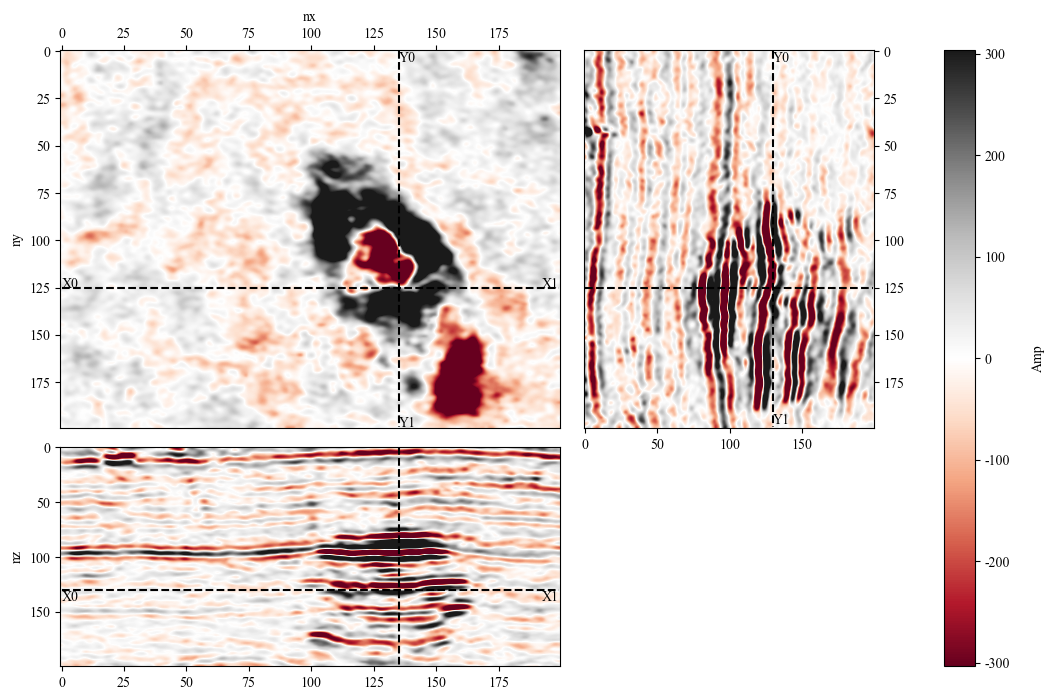

In [43]:
data_pred=preds.squeeze().detach().cpu().numpy()
plot_slices(data_pred, ids=[135,125,130], aspect='auto', size=8, cbar_label='Amp', interpolation='bicubic', cmap="RdGy",vmin=-vm,vmax=vm)

In [29]:
np.save("/home/max0b/IP_inversion_NO/data_eage2026/data_mintor.npy",data*gain)
np.save("/home/max0b/IP_inversion_NO/data_eage2026/data_mintor_pred.npy",data_pred)